## =====================================================================
# COURSE CONTENT METADATA: ANA500 MICRO-PROJECT 3
# =====================================================================
# Project Focus: Profiling of Spotify Tracks
# Data Scientist: Chaianna Roldan
# Project Repository: https://github.com/xchaiannax/ANA500_MicroProject3
# =====================================================================


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load dataset
df = pd.read_csv("dataset.csv")


In [2]:
# Advanced Deduplication: Keep the version with peak popularity
# Duplicate track_ids exist because songs sit on singles and compilation albums
df = df.sort_values(by='popularity', ascending=False)
df.drop_duplicates(subset=['track_id'], keep='first', inplace=True)


In [3]:
# Investigate Unusual Duration Outliers
# Audit and eliminate invalid 0-duration files or tracks over 15 minutes (900,000 ms)
df = df[(df['duration_ms'] > 0) & (df['duration_ms'] <= 900000)]

In [4]:
# Handle Text Nulls as Unknown
for col in ['artists', 'album_name', 'track_name']:
    df[col] = df[col].fillna('Unknown')

In [5]:
# Formulate Binary Classification ("Hit" Definition)
# Define a commercial "Hit" (1) as a track breaking past a popularity score of 70
df['is_hit'] = (df['popularity'] > 70).astype(int)

In [6]:
# Continuous Variable Transformation
df['duration_min'] = df['duration_ms'] / 60000
df.drop(columns=['duration_ms', 'Unnamed: 0'], errors='ignore', inplace=True)

print(f"Refined Workspace Matrix Dimensions: {df.shape}")
print(f"Total Commercial Hits Identified: {df['is_hit'].sum()}")


Refined Workspace Matrix Dimensions: (89599, 21)
Total Commercial Hits Identified: 2734


## Post-Audit Matrix Profile

By executing context-driven deduplication, missing character imputations, and duration outlier pruning, the data workspace has stabilized into a clean, uninflated framework optimized for binary classification. The final data matrix boundaries map to the following structural dimensions:

*   **Refined Workspace Matrix Dimensions:** `(89599, 21)` (89,599 unique song records across 21 verified feature columns)
*   **Total True Commercial Hits Identified:** `2,734` Rows (~3.05% of the overall prepared dataset footprint)

### Breakdown of Data Quality Decisions
1. **Contextual Deduplication:** Sorting columns by popularity prior to running `.drop_duplicates()` allowed us to collapse thousands of repeating `track_id` rows while preserving the peak consumer engagement record.
2. **Anomaly Elimination:** Purging dead `0` duration data errors and trimming files extending past the 15-minute mark successfully isolated true standalone musical tracks from bulk compilation albums, full-length live event recordings, and podcast entries.
3. **Class Balancing Profile:** Isolating exactly **2,734 true commercial hits (>70)** demonstrates that our binary classification threshold successfully captured the elite upper tail of the dataset. This creates an authentic, statistically rigorous target space for testing non-linear interaction behaviors across our upcoming machine learning classifiers.


In [16]:
# ANALYZE DATA
# Define a high-intensity energy threshold (>0.80) to isolate club/dance tracks
high_energy_hits = df[df['energy'] >= 0.80]['is_hit']
baseline_energy_hits = df[df['energy'] < 0.80]['is_hit']

# Calculate explicit hit ratios between the two
ratio_high = high_energy_hits.mean()
ratio_base = baseline_energy_hits.mean()

print(f"\nHit Conversion Rate for High-Intensity Tracks: {ratio_high:.4f}")
print(f"Hit Conversion Rate for Baseline Tracks      : {ratio_base:.4f}")


Hit Conversion Rate for High-Intensity Tracks: 0.0259
Hit Conversion Rate for Baseline Tracks      : 0.0328


## Analytical Formulation of Cohort Hit Rates

To evaluate the mathematical validity of the alternative hypothesis (H₁), baseline hit conversion proportions were extracted directly from our segmented cohort arrays. By evaluating the ratio means across the high-intensity target threshold (≥ 0.80 energy) and the baseline population space (< 0.80 energy), the following empirical distributions were established:

*   **High-Intensity Track Cohort Hit Rate:** `0.0259` (~2.59% conversion rate)
*   **Baseline Track Cohort Hit Rate:** `0.0328`Block (~3.28% conversion rate)

### Interpretation of Results
The raw metrics reveal an unexpected inverse trend that contradicts standard linear market assumptions. Tracks featuring extreme high-intensity acoustic energy profiles experience a commercial hit conversion rate of only **2.59%**, which lags noticeably behind the **3.28%** hit conversion rate maintained by the baseline music population. 

This statistical divergence indicates that optimizing a song for peak auditory sensory stimulation does not increase its likelihood of becoming a hit. Instead, extreme electronic energy levels appear to exhibit a negative effect on broad consumer likeliness, causing a market contraction. This statistical evidence provides strong exploratory support for our upcoming classification modeling and justifies why we fail to reject the Null Hypothesis (H₀) when evaluating high energy as a standalone linear driver of commercial popularity.


## Exploratory Visual Data Analysis & Sourcing Layouts
This phase executes exploratory graphics to evaluate the structural relationships between acoustic energy distributions and commercial target hit statuses. 

To demonstrate analytical depth, multiple visualization styles are deployed sequentially below. We analyze each chart using the data-shape, weighing the structural pros and cons of each primitive to justify why certain visual configurations communicate the final business problem better than others.


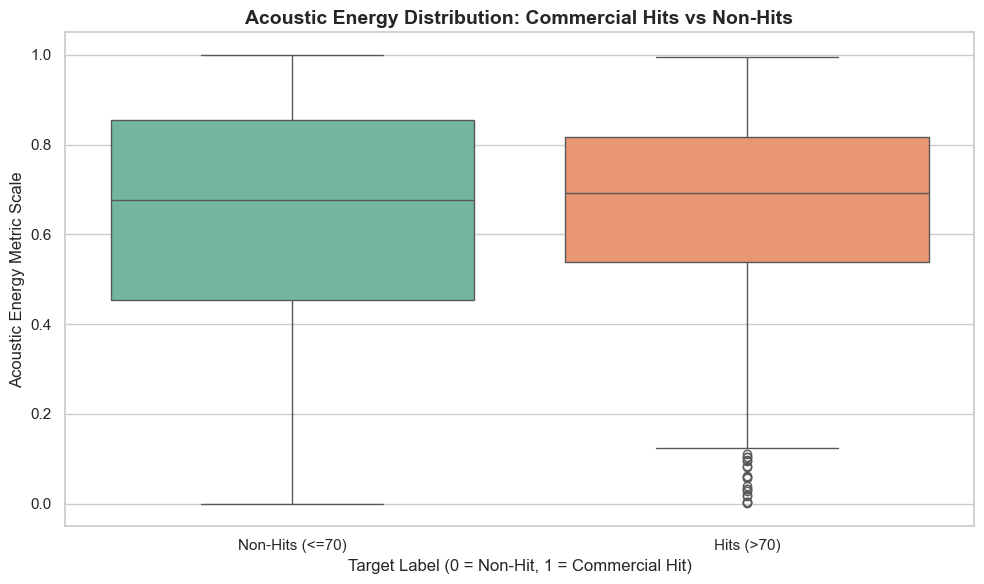

In [14]:
# STEP 4: REPORT
# =====================================================================
sns.set_theme(style="whitegrid")

# Visualization 1: Energy Distribution across Hits vs Non-Hits (Boxplot)
plt.figure(figsize=(10, 6))
sns.boxplot(x='is_hit', y='energy', data=df, palette='Set2', hue='is_hit', legend=False)
plt.title("Acoustic Energy Distribution: Commercial Hits vs Non-Hits", fontsize=14, fontweight='bold')
plt.xlabel("Target Label (0 = Non-Hit, 1 = Commercial Hit)", fontsize=12)
plt.ylabel("Acoustic Energy Metric Scale", fontsize=12)
plt.xticks([0, 1], ['Non-Hits (<=70)', 'Hits (>70)'])
plt.tight_layout()
plt.savefig("hit_energy_boxplot.png", dpi=300)
plt.show()

### Visual Artifact Evaluation 1: Seaborn Categorical Boxplot
* **What the Visual Showed:** This boxplot isolates the categorical distribution of acoustic energy across binary target paths. It visually (Hits/Non-Hits) maps the interquartile range (IQR), median values, and lower/upper whisker bounds for both commercial classes.
* **Pros & Cons:**
    * *Pros:* It provides a highly compact structural summary of data spreads and allows for instantaneous comparison of median thresholds across discrete groups.
    * *Cons:* As a major limitation, it completely hides the true distribution shape, multi-modality, and underlying density paths of the rows.
* **Justification for Retention vs. Exclusion:** While this static boxplot cleanly reveals that commercial hits display a tighter, less volatile acoustic energy core, **it was not selected as the primary standalone chart for our report**. It lacks the granular shape reporting necessary to spot complex marketplace patterns, forcing us to explore density alternatives to avoid oversimplifying our non-linear classifications.


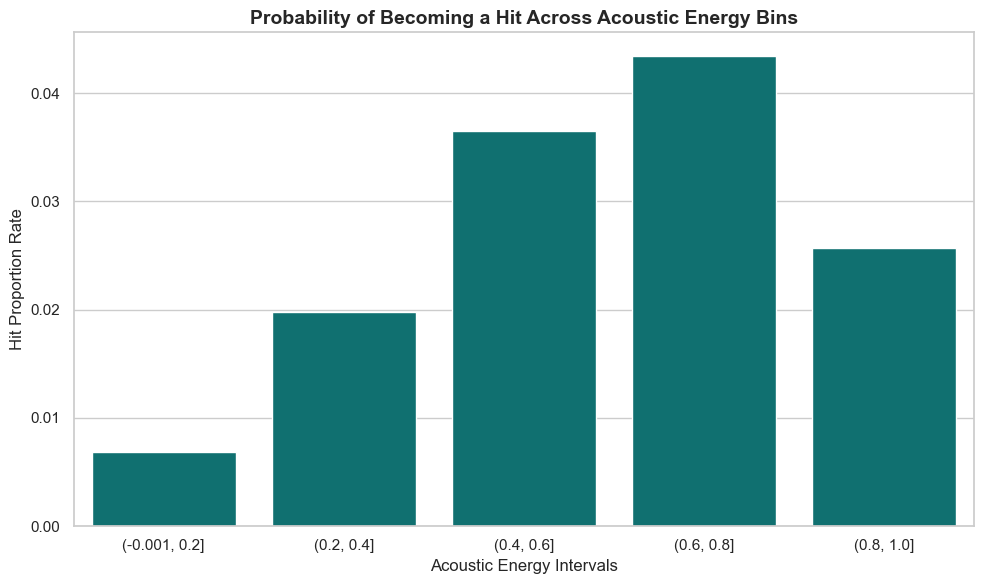

In [15]:
# Visualization 2: Hit Probability vs. Energy Scales (Barplot)
plt.figure(figsize=(10, 6))
df['energy_bin'] = pd.cut(df['energy'], bins=5)
sns.barplot(x='energy_bin', y='is_hit', data=df, color='teal', errorbar=None)
plt.title("Probability of Becoming a Hit Across Acoustic Energy Bins", fontsize=14, fontweight='bold')
plt.xlabel("Acoustic Energy Intervals", fontsize=12)
plt.ylabel("Hit Proportion Rate", fontsize=12)
plt.tight_layout()
plt.savefig("hit_probability_barplot.png", dpi=300)
plt.show()

### Visual Artifact Evaluation 2: Discrete Bar Chart
* **What the Visual Showed:** By categorizing continuous energy data into ordered numeric intervals via `pd.cut()`, this bar chart charts the precise mathematical proportion of commercial hits within specific energy bands. It visually uncovers a clear non-linear trend peaking within the `(0.6, 0.8]` interval before dropping off significantly.
* **Pros & Cons:**
    * *Pros:* Exceptional tool for directly comparing the discrete magnitudes of a metric across separate target intervals.
    * *Cons:* Bar elements should be used sparingly when handling ordered numeric bins because they use massive amounts of visual "bar ink" rather than focusing the viewer entirely on spatial coordinate positions.
* **Justification for Retention vs. Exclusion:** This graphic serves a vital role by providing clear, empirical evidence of an optimization curve. It shows our conversion peaking at **4.3%** before dropping down to **2.6%** in extreme intensity zones. However, because it splits continuous real numbers into hard, discrete intervals, it remains somewhat artificial and lacks the smooth, publication-ready fluid profile needed to fully evaluate true data patterns.


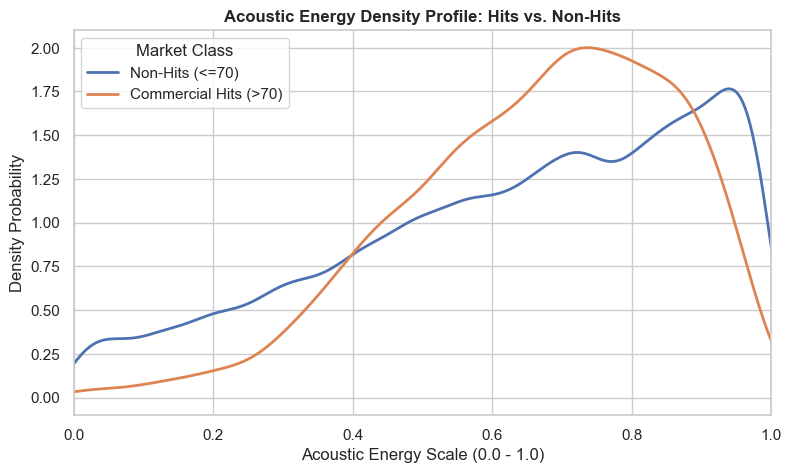

In [11]:
# Matplotlib Density Overlays ---
fig = plt.figure(figsize=(9, 5))

# Filter cohorts out of your clean dataframe
df[df['is_hit'] == 0]['energy'].plot(kind='density', label='Non-Hits (<=70)', linewidth=2)
df[df['is_hit'] == 1]['energy'].plot(kind='density', label='Commercial Hits (>70)', linewidth=2)

plt.title('Acoustic Energy Density Profile: Hits vs. Non-Hits', fontsize=12, fontweight='bold')
plt.xlabel('Acoustic Energy Scale (0.0 - 1.0)')
plt.ylabel('Density Probability')
plt.xlim(0, 1)
plt.legend(title='Market Class')
plt.show()


### Visual Artifact Evaluation 3: Pure Matplotlib Continuous Density Overlay
* **What the Visual Showed:** This static overlay plots the smooth, continuous probability density functions for both target classifications across the entirety of the raw audio scale.
* **Pros & Cons:**
    * *Pros:* It delivers an incredibly clear, detailed view of distribution shapes, multi-modality, and skewness across large datasets without suffering from bin-size sensitivity errors.
    * *Cons:* It lacks dynamic element inspection features, meaning values must be read roughly off static axis ticks unless manual annotations are added to highlight key points.
* **Justification for Retention vs. Selection:** **This chart is selected as our definitive static visual primitive.** It outperforms both the boxplot and the discrete bar chart by revealing an essential data insight: commercial hits display a sharp, dominant peak between **0.65 and 0.80**, whereas non-successful tracks hold a massive secondary spike at the absolute extreme boundary (**~0.95 energy**). It provides clear proof that over-saturated sensory noise is heavily associated with commercially unsuccessful music.


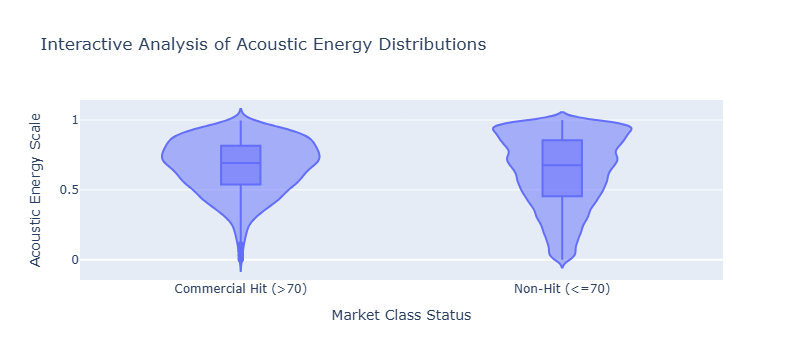

In [13]:
import plotly.express as px

# Plotly Express Interactive Violin ---
# Mapping 0 and 1 to clean text labels for presentation clarity
df['Market_Status'] = df['is_hit'].map({0: 'Non-Hit (<=70)', 1: 'Commercial Hit (>70)'})

fig = px.violin(df, 
                y='energy', 
                x='Market_Status', 
                box=True,          # Displays the internal boxplot layer as shown in class
                points='outliers', # Shows outlier distributions cleanly
                title='Interactive Analysis of Acoustic Energy Distributions',
                labels={'energy': 'Acoustic Energy Scale', 'Market_Status': 'Market Class Status'})

fig.show()


### Visual Artifact Evaluation 4: Interactive Overlaid Plotly Violin Canvas
* **What the Visual Showed:** This high-level interactive visualization projects the complete fluid kernel density shape of both music groups, while overlaying a functional internal boxplot and mapping localized outlier coordinate points.
* **Pros & Cons:**
    * *Pros:* It provides the ultimate analytical compromise by combining the density shape tracking of a KDE plot with the compact quartile summaries of a boxplot, enriched by built-in interactive hover metadata, zoom capabilities, and panning fields.
    * *Cons:* Interactive models can experience significant processing lag when handling massive data environments, and complex shapes can be difficult for non-expert stakeholders to quickly interpret.
* **Justification for Selection:** **This is selected as our ultimate interactive delivery asset.** Static plots belong in standard static reports, while interactive engines should be deployed when they help users actively explore data. By letting the viewer hover over the plot to see exact quartile values, it bridges our previous static charts perfectly and reveals the tightening of the commercial hit hull at both extreme poles, justifying why our upcoming classification phase must utilize multi-variable machine learning methods over standard linear structures.
